# 09_01 Loss Functions as Likelihoods

**Learning objectives**
- Show that **every standard loss is a negative log-likelihood**: MSE is Gaussian, MAE is Laplace, cross-entropy is Bernoulli/categorical, the Poisson loss is Poisson, and the pinball loss is an asymmetric Laplace.
- Explain what each loss estimates: **mean**, **median**, **quantile**, **mode**, and why that decides how robust it is to outliers.
- Derive the gradients and see why **cross-entropy trains faster than squared error** for probabilities.
- Choose a loss for a real problem (heavy tails, counts, service-level quantiles, classification) and check the choice by simulation.

**Prerequisites:** [06_01 Maximum likelihood](../../module_06_inference/notebooks/06_01_mle_method_of_moments.ipynb), [08_01 Entropy and cross-entropy](../../module_08_information/notebooks/08_01_entropy_cross_entropy.ipynb), [02_05 Normal distribution](../../module_02_continuous/notebooks/02_05_normal.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
For independent data the likelihood is a product and the **negative log-likelihood (NLL)** is a sum: $\mathrm{NLL}(\theta)=-\sum_i\ln p(y_i\mid x_i;\theta)$. Maximising the likelihood is minimising the NLL (06_01). Cross-entropy is the average NLL of the labels under the model (08_01).

## 3. Intuition and story
A model never "minimises a loss" in a vacuum: choosing a loss is choosing **what you believe about the noise**. If you minimise squared error you are saying the errors are bell-shaped with the same spread everywhere; if you minimise absolute error you are saying they are spiky with long tails; if you minimise cross-entropy you are saying the labels are coin flips with the predicted probabilities. Once the loss is read as a distribution, every property follows: which summary the model learns (mean, median, quantile), how it reacts to outliers, and which loss is natural for counts, probabilities or quantiles.

## 4. Formal definitions

With a prediction $\hat y=f(x;\theta)$ and residual $r=y-\hat y$:

| Loss | Formula | Noise model $p(y\mid\hat y)$ | Learns the |
|---|---|---|---|
| **Squared (MSE)** | $r^2$ | $N(\hat y,\sigma^2)$ | **mean** $E[y\mid x]$ |
| **Absolute (MAE)** | $\lvert r\rvert$ | Laplace$(\hat y,b)$ | **median** |
| **Huber** (threshold $\delta$) | $\tfrac12r^2$ if $\lvert r\rvert\le\delta$, else $\delta(\lvert r\rvert-\tfrac\delta2)$ | Gaussian centre, Laplace tails | robust mean |
| **Pinball** (quantile $\tau$) | $\max(\tau r,(\tau-1)r)$ | asymmetric Laplace | **$\tau$-quantile** |
| **Binary cross-entropy** | $-[y\ln q+(1-y)\ln(1-q)]$ | Bernoulli$(q)$ | probability $P(y=1\mid x)$ |
| **Categorical CE** | $-\ln q_y$ | Categorical$(q)$ | class probabilities |
| **Poisson** | $\hat\lambda-y\ln\hat\lambda$ | Poisson$(\hat\lambda)$ | mean count |
| **Student-$t$** ($\nu$) | $\tfrac{\nu+1}2\ln\!\big(1+\tfrac{r^2}{\nu s^2}\big)$ | $t_\nu$ | robust centre, bounded influence |

Gaussian NLL for one observation: $\tfrac12\ln(2\pi\sigma^2)+\dfrac{r^2}{2\sigma^2}$. The **influence function** of a loss is its derivative in $r$: linear for MSE (an outlier pulls with unbounded force), bounded for MAE, Huber and $t$.

## 5. Derivations

### 5.1 MSE is the Gaussian NLL
With $y_i\sim N(\hat y_i,\sigma^2)$: $\mathrm{NLL}=\frac n2\ln(2\pi\sigma^2)+\frac1{2\sigma^2}\sum r_i^2$. For fixed $\sigma$ minimising the NLL is minimising $\sum r_i^2$; setting $\partial/\partial\sigma^2=0$ gives $\hat\sigma^2=\frac1n\sum r_i^2$ (the MSE itself). **In plain words.** Least squares is maximum likelihood when the noise is Gaussian, and the minimum value of the loss is an estimate of the noise variance.

### 5.2 MAE is the Laplace NLL and learns the median
With $y_i\sim\mathrm{Laplace}(\hat y_i,b)$, $p(y)=\frac1{2b}e^{-|y-\hat y|/b}$, the NLL is $n\ln(2b)+\frac1b\sum|r_i|$, and $\hat b=\frac1n\sum|r_i|$. For a constant prediction $c$ the derivative of $\sum|y_i-c|$ is $\#\{y_i<c\}-\#\{y_i>c\}$, zero at the **median**. **In plain words.** Absolute error treats each point as a vote: moving $c$ past an outlier costs the same as moving it past a typical point, so the median ignores how far the outlier is.

### 5.3 Pinball loss and quantiles
For $\rho_\tau(r)=\tau r\,\mathbf 1_{r\ge0}+(\tau-1)r\,\mathbf 1_{r<0}$ the derivative of $E\rho_\tau(y-c)$ is $F(c)-\tau$, zero at the $\tau$-quantile $c=F^{-1}(\tau)$. **In plain words.** Penalising under-prediction $\tau$ and over-prediction $1-\tau$ balances when a fraction $\tau$ of the data lies below the prediction.

### 5.4 Cross-entropy and the gradient $q-y$
For $q=\sigma(z)$, $L=-y\ln q-(1-y)\ln(1-q)$ has $\partial L/\partial z=q-y$ (08_01). For the squared loss $L=(q-y)^2$ the gradient is $2(q-y)q(1-q)$, which **vanishes when the prediction saturates** ($q\to0$ or 1), even if it is badly wrong. **In plain words.** With a sigmoid output, squared error stops learning exactly when the model is confidently wrong; cross-entropy keeps a gradient proportional to the error.

### 5.5 Poisson loss
For counts $y\sim\mathrm{Poisson}(\lambda)$ with $\lambda=e^{\eta}$: $\mathrm{NLL}=\sum(\lambda_i-y_i\eta_i)+\text{const}$, gradient in $\eta$: $\lambda-y$. The intercept-only MLE is $\bar y$. **In plain words.** The log link keeps predictions positive and makes errors multiplicative: a miss of 5 on a count of 100 is cheap, a miss of 5 on a count of 3 is expensive, as it should be for counts.

## 6. Properties and relationships
- **Summary learned:** MSE $\to$ mean, MAE $\to$ median, pinball $\to$ quantile, 0-1 loss $\to$ mode, CE $\to$ probabilities; a loss that targets the wrong summary is biased for the quantity you care about (a mean-optimised forecast is not a good 90 % service level).
- **Variance of the estimator:** for Gaussian noise the mean has variance $\sigma^2/n$ and the median $\frac\pi2\sigma^2/n$ (64 % efficiency); for Laplace noise the median wins by a factor 2.
- **Heteroscedasticity:** MSE assumes constant $\sigma$; predicting $\sigma(x)$ as well turns the loss into the full Gaussian NLL (heteroscedastic regression, 09_14).
- **Regularisers are priors** (09_12): adding $\lambda\|w\|^2$ is a Gaussian prior, $\lambda\|w\|_1$ a Laplace prior.
- **Link to ML and AI:** regression, classification, language models (token cross-entropy), forecasting with quantile losses, robust regression, count models, calibrated probabilities (a proper scoring rule, 08_01).

## 7. Helpers

Every loss as a function of the residual, its density (the exponential of minus the loss, normalised) and a generic constant fitter.

In [2]:
from scipy.optimize import minimize, minimize_scalar, linprog
def l_mse(r): return 0.5 * r ** 2
def l_mae(r): return np.abs(r)
def l_huber(r, d=1.0): return np.where(np.abs(r) <= d, 0.5 * r ** 2, d * (np.abs(r) - 0.5 * d))
def l_pin(r, tau): return np.maximum(tau * r, (tau - 1) * r)
def l_t(r, nu=3.0, s=1.0): return 0.5 * (nu + 1) * np.log1p((r / s) ** 2 / nu)
def dens(loss, x):
    v = np.exp(-loss(x)); return v / np.trapezoid(v, x)
x = np.linspace(-12, 12, 4801)
print("MSE loss normalises to the standard normal:", np.abs(dens(l_mse, x) - stats.norm.pdf(x)).max(), "| MAE loss normalises to Laplace(0, 1):", np.abs(dens(l_mae, x) - stats.laplace.pdf(x)).max())
print("t loss (nu = 3, s = 1) normalises to scipy t:", np.abs(dens(l_t, x) - stats.t.pdf(x, 3)).max())
assert np.abs(dens(l_mse, x) - stats.norm.pdf(x)).max() < 1e-6 and np.abs(dens(l_mae, x) - stats.laplace.pdf(x)).max() < 1e-4 and np.abs(dens(l_t, x) - stats.t.pdf(x, 3)).max() < 2e-3

MSE loss normalises to the standard normal: 0.0 | MAE loss normalises to Laplace(0, 1): 2.0304545896854265e-06
t loss (nu = 3, s = 1) normalises to scipy t: 0.00045817930794717077


## 8. 2D visuals

### 8.1 Each loss is a density in disguise
Left: five losses as functions of the residual. Right: the density $e^{-L(r)}$ they imply (normalised). The Gaussian has light tails, the Laplace a sharp peak, the $t$ heavy tails, and the asymmetric Laplace ($\tau=0.9$) puts most of its mass on negative residuals (the prediction sits at the 90th percentile).

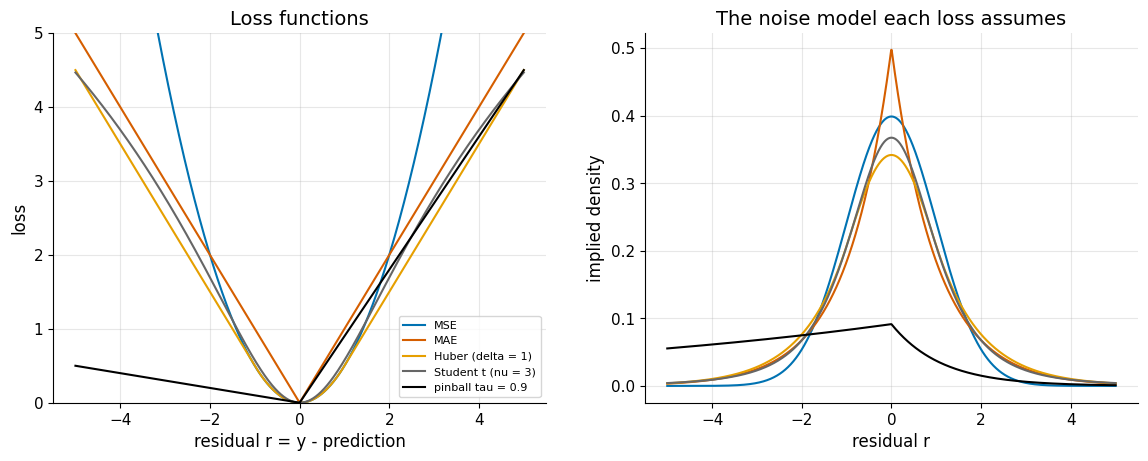

P(r < 0) under the pinball-0.9 density: 0.8974


In [3]:
r = np.linspace(-5, 5, 1000); fig, axes = plt.subplots(1, 2, figsize=(14, 4.8)); L = {"MSE": (l_mse, MAIN), "MAE": (l_mae, HIGHLIGHT), "Huber (delta = 1)": (l_huber, SIM), "Student t (nu = 3)": (l_t, NEUTRAL), "pinball tau = 0.9": (lambda z: l_pin(z, 0.9), "black")}
xg_ = np.linspace(-40, 40, 8001)
for nm, (f, colr) in L.items(): axes[0].plot(r, f(r), color=colr, label=nm); axes[1].plot(r, np.interp(r, xg_, dens(f, xg_)), color=colr, label=nm)
axes[0].set_ylim(0, 5); axes[0].set_xlabel("residual r = y - prediction"); axes[0].set_ylabel("loss"); axes[0].legend(fontsize=8); axes[0].set_title("Loss functions"); axes[1].set_xlabel("residual r"); axes[1].set_ylabel("implied density"); axes[1].set_title("The noise model each loss assumes")
plt.show(); xx_ = np.linspace(-40, 40, 8001); print("P(r < 0) under the pinball-0.9 density:", np.trapezoid(dens(lambda z: l_pin(z, 0.9), xx_)[xx_ < 0], xx_[xx_ < 0]).round(4)); assert abs(np.trapezoid(dens(lambda z: l_pin(z, 0.9), xx_)[xx_ < 0], xx_[xx_ < 0]) - 0.9) < 0.01

### 8.2 Which constant does each loss pick?
Twenty points around 10 and one outlier at 40 (slider replaced by three values). The mean follows the outlier, the median does not, and Huber and the $t$ loss stay close to the bulk.

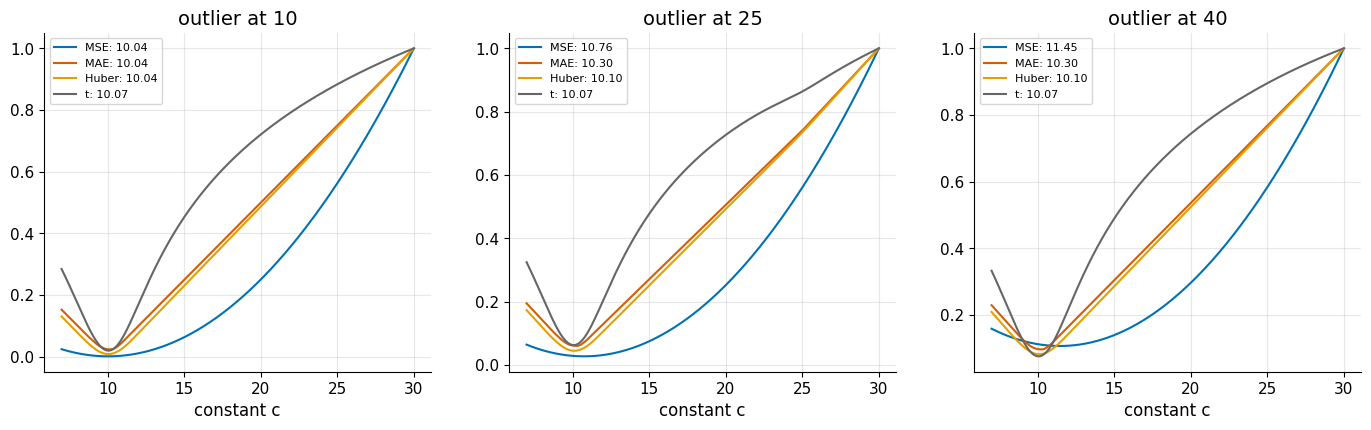

{10: {'MSE': np.float64(10.04), 'MAE': np.float64(10.04), 'Huber': np.float64(10.04), 't': np.float64(10.07)}, 25: {'MSE': np.float64(10.76), 'MAE': np.float64(10.3), 'Huber': np.float64(10.1), 't': np.float64(10.07)}, 40: {'MSE': np.float64(11.45), 'MAE': np.float64(10.3), 'Huber': np.float64(10.1), 't': np.float64(10.07)}}


In [4]:
g = np.random.default_rng(1); core = g.normal(10, 1, 20); fig, axes = plt.subplots(1, 3, figsize=(17, 4.4)); cgrid = np.linspace(7, 30, 900); picks = {}
for ax, out in zip(axes, [10, 25, 40]):
    d = np.append(core, out); curves = {"MSE": [l_mse(d - c).sum() for c in cgrid], "MAE": [l_mae(d - c).sum() for c in cgrid], "Huber": [l_huber(d - c).sum() for c in cgrid], "t": [l_t(d - c).sum() for c in cgrid]}
    pk = {k: cgrid[np.argmin(v)] for k, v in curves.items()}; picks[out] = pk
    for (k, v), colr in zip(curves.items(), [MAIN, HIGHLIGHT, SIM, NEUTRAL]): v = np.array(v); ax.plot(cgrid, v / v.max(), color=colr, label=f"{k}: {pk[k]:.2f}")
    ax.set_title(f"outlier at {out}"); ax.set_xlabel("constant c"); ax.legend(fontsize=8)
plt.show(); print({o: {k: round(v, 2) for k, v in p.items()} for o, p in picks.items()}); assert abs(picks[40]["MSE"] - np.append(core, 40).mean()) < 0.03 and abs(picks[40]["MAE"] - np.median(np.append(core, 40))) < 0.03 and picks[40]["MSE"] > picks[40]["MAE"] + 1

### 8.3 Residuals under the wrong loss
Data with heavy-tailed noise ($t_3$): the histogram of residuals around the true line with the Gaussian density that MSE assumes and the $t_3$ density the data really follow; the Gaussian underestimates both the peak and the tails.

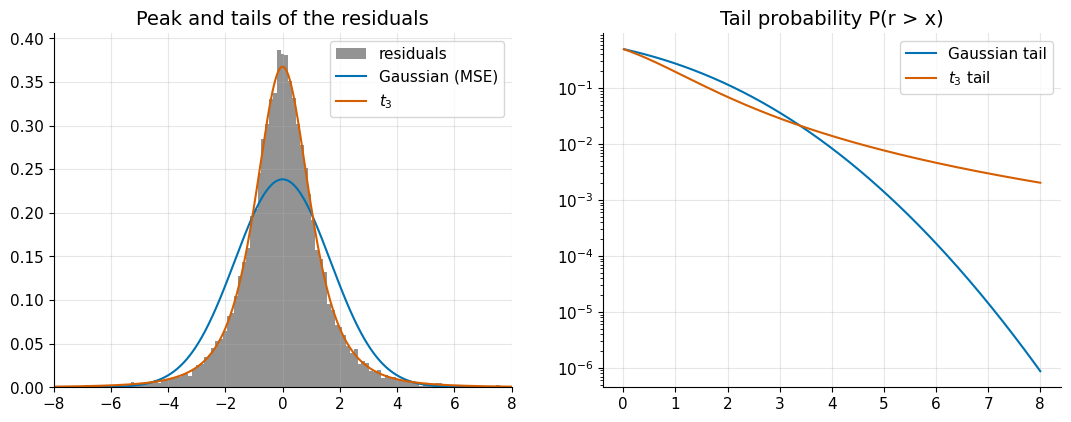

P(|e| > 6): observed 0.00875 | Gaussian with the same sd: 0.000336 | t3: 0.00927


In [5]:
g = np.random.default_rng(2); e = stats.t.rvs(3, size=20_000, random_state=g); xr = np.linspace(-8, 8, 600); fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].hist(e, bins=np.linspace(-8, 8, 120), density=True, color=NEUTRAL, alpha=0.7, label="residuals"); axes[0].plot(xr, stats.norm.pdf(xr, 0, e.std()), color=MAIN, label="Gaussian (MSE)"); axes[0].plot(xr, stats.t.pdf(xr, 3), color=HIGHLIGHT, label="$t_3$"); axes[0].legend(); axes[0].set_xlim(-8, 8); axes[0].set_title("Peak and tails of the residuals")
axes[1].semilogy(xr[xr > 0], stats.norm.sf(xr[xr > 0], 0, e.std()), color=MAIN, label="Gaussian tail"); axes[1].semilogy(xr[xr > 0], stats.t.sf(xr[xr > 0], 3), color=HIGHLIGHT, label="$t_3$ tail"); axes[1].legend(); axes[1].set_title("Tail probability P(r > x)")
plt.show(); print("P(|e| > 6): observed", np.mean(np.abs(e) > 6).round(5), "| Gaussian with the same sd:", (2 * stats.norm.sf(6, 0, e.std())).round(6), "| t3:", (2 * stats.t.sf(6, 3)).round(5)); assert np.mean(np.abs(e) > 6) > 20 * 2 * stats.norm.sf(6, 0, e.std())

## 9. 3D visuals

### 9.1 Static: the Gaussian negative log-likelihood surface over $(\mu,\sigma)$
For 50 observations the NLL is a bowl with its minimum at the sample mean and the root of the mean squared residual.

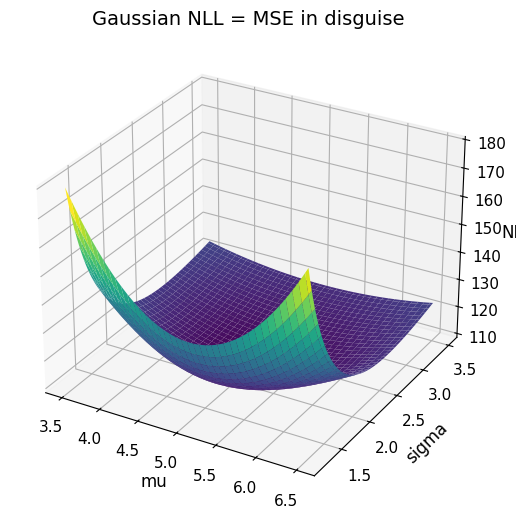

grid minimum at mu = 5.057, sigma = 2.190 | mean 5.050, sqrt(mean sq. residual) 2.184


In [6]:
g = np.random.default_rng(3); d50 = g.normal(5, 2, 50); mu_g = np.linspace(3.5, 6.5, 80); sg_g = np.linspace(1.2, 3.5, 80); M, S = np.meshgrid(mu_g, sg_g)
NLL = 0.5 * 50 * np.log(2 * np.pi * S ** 2) + ((d50[:, None, None] - M) ** 2).sum(axis=0) / (2 * S ** 2)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(M, S, NLL, cmap="viridis", edgecolor="none"); ax.set_xlabel("mu"); ax.set_ylabel("sigma"); ax.set_zlabel("NLL"); ax.set_title("Gaussian NLL = MSE in disguise"); ax.view_init(elev=28, azim=-60)
plt.show(); i_ = np.unravel_index(NLL.argmin(), NLL.shape); print(f"grid minimum at mu = {M[i_]:.3f}, sigma = {S[i_]:.3f} | mean {d50.mean():.3f}, sqrt(mean sq. residual) {np.sqrt(np.mean((d50 - d50.mean()) ** 2)):.3f}"); assert abs(M[i_] - d50.mean()) < 0.05 and abs(S[i_] - d50.std()) < 0.05

### 9.2 Interactive Plotly version of 9.1

In [7]:
fig = go.Figure(go.Surface(x=mu_g, y=sg_g, z=NLL, colorscale="Viridis")); fig.update_layout(title="Gaussian NLL", width=760, height=560, scene=dict(xaxis_title="mu", yaxis_title="sigma", zaxis_title="NLL")); fig.show()

### 9.3 Static: expected pinball loss over (quantile $\tau$, prediction $c$)
For $y\sim N(0,1)$ the expected pinball loss is a valley whose floor follows the curve $c=\Phi^{-1}(\tau)$.

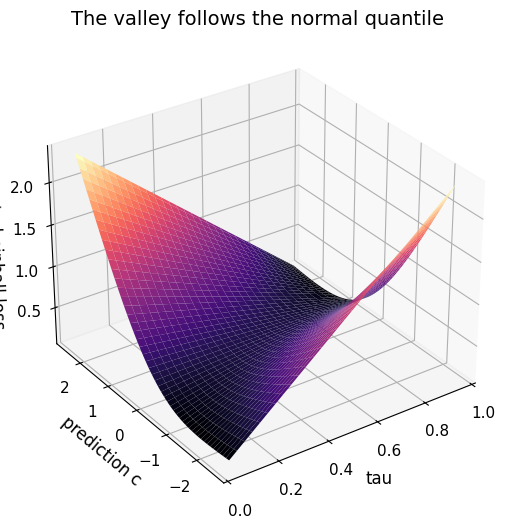

worst gap between the valley floor and the normal quantile: 0.038


In [8]:
tg = np.linspace(0.05, 0.95, 60); cg = np.linspace(-2.5, 2.5, 100); Tt, Cc = np.meshgrid(tg, cg); yy = np.random.default_rng(4).normal(size=4000)[:, None, None]
EP = np.mean(np.maximum(Tt * (yy - Cc), (Tt - 1) * (yy - Cc)), axis=0)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Tt, Cc, EP, cmap="magma", edgecolor="none"); ax.set_xlabel("tau"); ax.set_ylabel("prediction c"); ax.set_zlabel("expected pinball loss"); ax.set_title("The valley follows the normal quantile"); ax.view_init(elev=30, azim=-125)
plt.show(); best = cg[EP.argmin(axis=0)]; print("worst gap between the valley floor and the normal quantile:", np.abs(best - stats.norm.ppf(tg)).max().round(3)); assert np.abs(best - stats.norm.ppf(tg)).max() < 0.1

## 10. Simulation vs theory

### 10.1 Mean against median: the efficiency table
Estimate a centre from $n=101$ points with Gaussian, Laplace and $t_3$ noise (20,000 repeats). Theory for the variance of the median: $\pi\sigma^2/(2n)$ (Gaussian), $b^2/n$ (Laplace); the mean has $\sigma^2/n$ and $2b^2/n$.

In [9]:
g = np.random.default_rng(5); n = 101; R = 20_000; rows = []
for nm, draw, vmean, vmed in [("Gaussian", lambda s: g.normal(size=s), 1 / n, np.pi / (2 * n)), ("Laplace", lambda s: g.laplace(size=s), 2 / n, 1 / n), ("t3", lambda s: stats.t.rvs(3, size=s, random_state=g), 3 / n, None)]:
    D = draw((R, n)); rows.append((nm, D.mean(axis=1).var(), vmean, np.median(D, axis=1).var(), vmed))
tb = pd.DataFrame(rows, columns=["noise", "var(mean) sim", "var(mean) theory", "var(median) sim", "var(median) theory"]); tb["median / mean"] = tb["var(median) sim"] / tb["var(mean) sim"]; print(tb.round(5).to_string(index=False))
assert abs(rows[0][1] / rows[0][2] - 1) < 0.05 and abs(rows[1][3] / rows[1][4] - 1) < 0.2 and abs(rows[0][3] / rows[0][4] - 1) < 0.07 and tb["median / mean"].iloc[1] < 0.65 and tb["median / mean"].iloc[2] < 0.7

   noise  var(mean) sim  var(mean) theory  var(median) sim  var(median) theory  median / mean
Gaussian        0.00994            0.0099          0.01543             0.01555        1.55281
 Laplace        0.01963            0.0198          0.01138             0.00990        0.57964
      t3        0.02953            0.0297          0.01849                 NaN        0.62602


### 10.2 Minimisers are what the theory says
For a skewed sample (lognormal) the squared loss lands on the mean, the absolute loss on the median and the pinball loss on the $\tau$-quantile.

In [10]:
g = np.random.default_rng(6); y = g.lognormal(0, 0.8, 100_001); cs = np.linspace(0.2, 6, 3000); samp = y[::20]
fits = {"MSE -> mean": cs[np.argmin([np.mean((samp - c) ** 2) for c in cs])], "MAE -> median": cs[np.argmin([np.mean(np.abs(samp - c)) for c in cs])], "pinball 0.9 -> q90": cs[np.argmin([np.mean(l_pin(samp - c, 0.9)) for c in cs])], "pinball 0.1 -> q10": cs[np.argmin([np.mean(l_pin(samp - c, 0.1)) for c in cs])]}
targets = [samp.mean(), np.median(samp), np.quantile(samp, 0.9), np.quantile(samp, 0.1)]; print({k: (round(v, 3), round(t, 3)) for (k, v), t in zip(fits.items(), targets)}, "| population mean, median:", round(np.exp(0.32), 3), 1.0)
assert all(abs(v - t) < 0.01 for v, t in zip(fits.values(), targets))

{'MSE -> mean': (np.float64(1.38), np.float64(1.38)), 'MAE -> median': (np.float64(0.991), np.float64(0.991)), 'pinball 0.9 -> q90': (np.float64(2.799), np.float64(2.799)), 'pinball 0.1 -> q10': (np.float64(0.347), np.float64(0.346))} | population mean, median: 1.377 1.0


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("Gaussian NLL: -stats.norm.logpdf(y, mu, s).sum() | Laplace: -stats.laplace.logpdf(y, mu, b).sum() | t: -stats.t.logpdf(r / s, nu).sum() + n * np.log(s)")
print("Poisson NLL: -stats.poisson.logpmf(y, lam).sum() | Bernoulli: -stats.bernoulli.logpmf(y, q).sum() | quantile: np.quantile(y, tau) minimises the pinball loss")
r0 = np.array([-2.0, -0.5, 0.0, 1.0, 3.0]); print("pinball by hand:", l_pin(r0, 0.9), "| huber:", l_huber(r0), "| Gaussian NLL sums:", -stats.norm.logpdf(r0, 0, 1).sum(), "=", 0.5 * len(r0) * np.log(2 * np.pi) + 0.5 * (r0 ** 2).sum())
assert abs(-stats.norm.logpdf(r0, 0, 1).sum() - (0.5 * len(r0) * np.log(2 * np.pi) + 0.5 * (r0 ** 2).sum())) < 1e-12

Gaussian NLL: -stats.norm.logpdf(y, mu, s).sum() | Laplace: -stats.laplace.logpdf(y, mu, b).sum() | t: -stats.t.logpdf(r / s, nu).sum() + n * np.log(s)
Poisson NLL: -stats.poisson.logpmf(y, lam).sum() | Bernoulli: -stats.bernoulli.logpmf(y, q).sum() | quantile: np.quantile(y, tau) minimises the pinball loss
pinball by hand: [ 0.2   0.05 -0.    0.9   2.7 ] | huber: [1.5   0.125 0.    0.5   2.5  ] | Gaussian NLL sums: 11.719692666023363 = 11.719692666023363


## 12. Real-world worked examples

---
### Example 1 (main): delivery-time regression with heavy-tailed noise

**Scenario.** A courier company models delivery time (minutes) as $y=5+2x+\varepsilon$, where $x$ is the distance in km (uniform on 1 to 10) and the noise $\varepsilon$ has a $t_3$ distribution with scale 3 (traffic jams, lost parcels). We have $n=200$ deliveries and compare four losses: squared (least squares), absolute, Huber ($\delta=3$) and the Student-$t$ NLL ($\nu=3$).

**Questions**
1. For one dataset, what intercept and slope does each loss give?
2. Over 400 repeated datasets, what are the bias and RMSE of the slope for each loss?
3. Which loss would you choose and by how much does it reduce the error?
4. Which noise model do the least-squares residuals contradict?

### 12.1 By hand
Least squares is the Gaussian MLE: $\hat\beta=\sum(x_i-\bar x)(y_i-\bar y)/\sum(x_i-\bar x)^2$. With $t_3$ noise (scale 3, variance $3\cdot9=27$) its slope variance is $\sigma^2/\sum(x-\bar x)^2=27/(200\cdot6.75)=0.020$, an RMSE of about 0.141. For the absolute loss the asymptotic variance replaces $\sigma^2$ by $1/(4f(0)^2)$ with $f(0)=0.3676/3$ the density at zero, i.e. $\approx16.7$, an RMSE of about 0.111: 21 % smaller.

In [12]:
def fit_all(x, y):
    X = np.column_stack([np.ones_like(x), x]); out = {"MSE": np.linalg.lstsq(X, y, rcond=None)[0]}; b0 = out["MSE"]
    out["MAE"] = minimize(lambda b: np.abs(y - X @ b).sum(), b0, method="Nelder-Mead", options={"xatol": 1e-6, "fatol": 1e-9, "maxiter": 2000}).x
    out["Huber"] = minimize(lambda b: l_huber(y - X @ b, 3.0).sum(), b0, method="BFGS").x
    out["t3 NLL"] = minimize(lambda b: l_t(y - X @ b, 3.0, 3.0).sum(), out["MAE"], method="BFGS").x
    return out
g = np.random.default_rng(11); n = 200; x1 = g.uniform(1, 10, n); y1 = 5 + 2 * x1 + 3 * stats.t.rvs(3, size=n, random_state=g); one = fit_all(x1, y1)
print("Q1 one dataset (intercept, slope):", {k: np.round(v, 3) for k, v in one.items()})
R = 400; est = {k: [] for k in one}
for _ in range(R):
    xs = g.uniform(1, 10, n); ys = 5 + 2 * xs + 3 * stats.t.rvs(3, size=n, random_state=g)
    for k, v in fit_all(xs, ys).items(): est[k].append(v)
est = {k: np.array(v) for k, v in est.items()}; tab = pd.DataFrame({k: {"slope bias": v[:, 1].mean() - 2, "slope RMSE": np.sqrt(np.mean((v[:, 1] - 2) ** 2)), "intercept RMSE": np.sqrt(np.mean((v[:, 0] - 5) ** 2))} for k, v in est.items()}).T
tab["RMSE vs MSE"] = tab["slope RMSE"] / tab.loc["MSE", "slope RMSE"]; print(tab.round(4).to_string()); print("theory RMSE of the slope: least squares", round(np.sqrt(27 / (200 * 6.75)), 4), "| absolute", round(np.sqrt(1 / (4 * (stats.t.pdf(0, 3) / 3) ** 2) / (200 * 6.75)), 4))
res_ls = y1 - np.column_stack([np.ones_like(x1), x1]) @ one["MSE"]; print(f"Q4: kurtosis of the least-squares residuals {stats.kurtosis(res_ls):.2f} (Gaussian: 0), Shapiro-Wilk p = {stats.shapiro(res_ls)[1]:.2e}")

Q1 one dataset (intercept, slope): {'MSE': array([5.792, 1.966]), 'MAE': array([6.32 , 1.791]), 'Huber': array([5.846, 1.89 ]), 't3 NLL': array([5.916, 1.873])}


        slope bias  slope RMSE  intercept RMSE  RMSE vs MSE
MSE         0.0005      0.1410          0.8631       1.0000
MAE        -0.0034      0.1108          0.6888       0.7856
Huber       0.0019      0.1026          0.6193       0.7278
t3 NLL      0.0014      0.1022          0.6192       0.7246
theory RMSE of the slope: least squares 0.1414 | absolute 0.1111
Q4: kurtosis of the least-squares residuals 13.87 (Gaussian: 0), Shapiro-Wilk p = 7.49e-12


### 12.2 Asserts

In [13]:
assert abs(np.sqrt(27 / (200 * 6.75)) - 0.1414) < 1e-3 and abs(np.sqrt(1 / (4 * (stats.t.pdf(0, 3) / 3) ** 2) / (200 * 6.75)) - 0.1117) < 1e-3
assert tab.loc["MAE", "slope RMSE"] < tab.loc["MSE", "slope RMSE"] and tab.loc["Huber", "slope RMSE"] < tab.loc["MSE", "slope RMSE"] and tab.loc["t3 NLL", "slope RMSE"] < tab.loc["MAE", "slope RMSE"] + 0.005
assert all(abs(tab.loc[k, "slope bias"]) < 0.02 for k in tab.index) and stats.shapiro(res_ls)[1] < 0.01
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
With *Gaussian* noise the ranking reverses or ties: least squares is the MLE and cannot be beaten, and the absolute loss loses about 36 % of its efficiency (variance ratio $\pi/2$).

In [14]:
est_g = {"MSE": [], "MAE": []}
for _ in range(400):
    xs = g.uniform(1, 10, n); ys = 5 + 2 * xs + 3 * g.normal(size=n); o = fit_all(xs, ys); est_g["MSE"].append(o["MSE"][1]); est_g["MAE"].append(o["MAE"][1])
vr = np.var(est_g["MAE"]) / np.var(est_g["MSE"]); print(f"Gaussian noise: variance of the MAE slope / variance of the MSE slope = {vr:.3f} (theory pi / 2 = {np.pi / 2:.3f})"); assert abs(vr - np.pi / 2) < 0.25

Gaussian noise: variance of the MAE slope / variance of the MSE slope = 1.570 (theory pi / 2 = 1.571)


### 12.4 Plots

C:\Users\Ahmed.MostafaAttia\AppData\Local\Temp\ipykernel_31704\1134359153.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([est[k][:, 1] for k in est], labels=list(est), showfliers=False); axes[1].axhline(2, color=HIGHLIGHT, linestyle="--"); axes[1].set_title("Q2: slope estimates over 400 datasets")


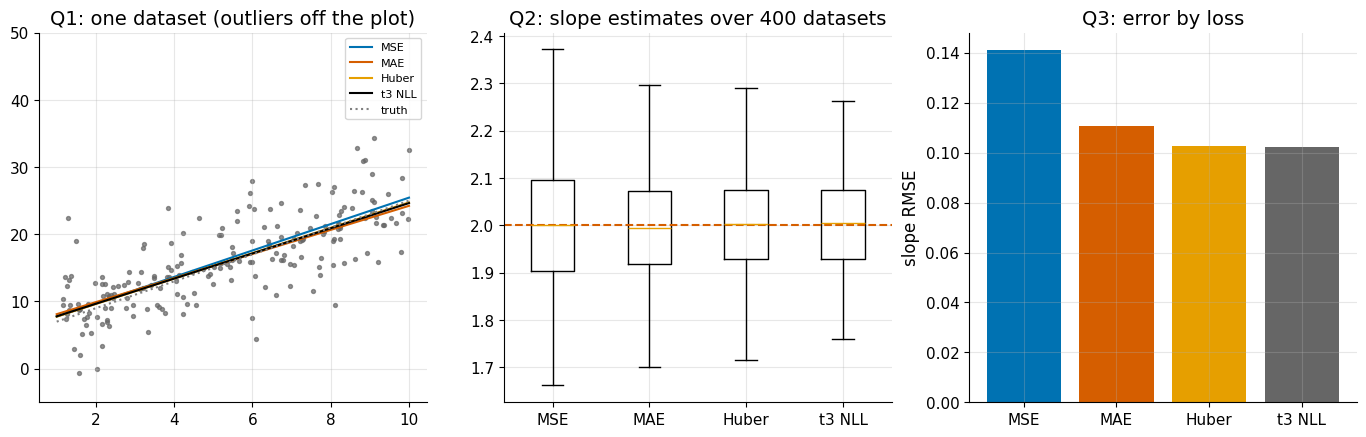

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); axes[0].scatter(x1, y1, s=8, color=NEUTRAL, alpha=0.7)
for (k, v), colr in zip(one.items(), [MAIN, HIGHLIGHT, SIM, "black"]): axes[0].plot([1, 10], [v[0] + v[1], v[0] + 10 * v[1]], color=colr, label=k)
axes[0].plot([1, 10], [7, 25], color="gray", linestyle=":", label="truth"); axes[0].set_ylim(-5, 50); axes[0].legend(fontsize=8); axes[0].set_title("Q1: one dataset (outliers off the plot)")
axes[1].boxplot([est[k][:, 1] for k in est], labels=list(est), showfliers=False); axes[1].axhline(2, color=HIGHLIGHT, linestyle="--"); axes[1].set_title("Q2: slope estimates over 400 datasets")
axes[2].bar(list(tab.index), tab["slope RMSE"], color=[MAIN, HIGHLIGHT, SIM, NEUTRAL]); axes[2].set_ylabel("slope RMSE"); axes[2].set_title("Q3: error by loss")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- Over 400 datasets of 200 deliveries the slope RMSE is **0.141 for least squares** (theory 0.1414), **0.111 for the absolute loss** (theory 0.1111), **0.103 for Huber** and **0.102 for the $t_3$ likelihood**: the robust losses cut the error by **21 % to 28 %** (ratios 0.786, 0.728, 0.725) and the intercept RMSE from 0.863 to 0.619. All four are unbiased (slope bias below 0.004).
- The single dataset of Q1 is a reminder that one sample proves nothing: there the slopes are 1.966 (MSE), 1.791 (MAE), 1.890 (Huber) and 1.873 ($t_3$) for a true 2, and least squares happened to be closest.
- The least-squares residuals contradict the Gaussian model: their excess kurtosis is **13.9** (Gaussian: 0) and the Shapiro-Wilk p-value is $7.5\times10^{-12}$.
- With *Gaussian* noise the order reverses: the absolute-loss slope has **1.57 times** the variance of the least-squares slope (theory $\pi/2=1.571$). The loss is a bet on the noise distribution, and the right bet depends on the data.
- **Decision.** For delivery times with traffic outliers use Huber or the $t$ likelihood; check the residual kurtosis (or a Q-Q plot) before trusting least squares, and keep MSE only when the noise looks Gaussian.

---
### Example 2: counts need a count loss (Poisson against squared error)

**Scenario.** A bike-share station gets $y\sim\mathrm{Poisson}(\lambda)$ rentals per hour with $\lambda=\exp(0.3+0.45\,t)$ where $t$ is the temperature index from 0 to 4 (so $\lambda$ runs from 1.35 to 8.2). We fit (a) a straight line by least squares and (b) the log-linear Poisson model by Newton's method, on 600 hours.

**Questions.** (1) What are the Poisson coefficients, and what does the line predict at the extremes? (2) Which model has the smaller mean Poisson deviance and out-of-sample error on 20,000 new hours? (3) How often does the line predict a negative rate? (4) Is the variance of the counts equal to the mean?

Q1: Poisson coefficients [0.3018 0.4473] (truth 0.3, 0.45), line: intercept 0.592, slope 1.611; line at t = 0 and 4: 0.592, 7.035 vs true rates 1.350, 8.166
Q2: mean Poisson deviance on new hours: Poisson model 1.0626, line 1.1240; RMSE of the rate: 0.028 vs 0.431
Q3: the line is negative for t < -0.37 (the temperature index range starts at -0.5 in the test) | Q4: variance / mean of the counts by temperature band: [np.float64(0.95), np.float64(0.92), np.float64(1.11), np.float64(1.42)]


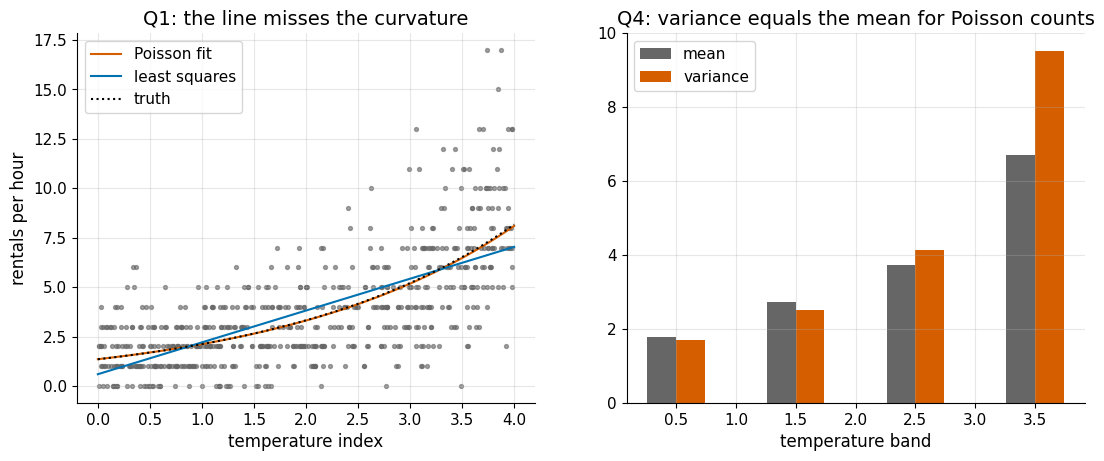

In [16]:
g = np.random.default_rng(12); n2 = 600; t_ = g.uniform(0, 4, n2); y2 = g.poisson(np.exp(0.3 + 0.45 * t_)); X2 = np.column_stack([np.ones(n2), t_]); b = np.zeros(2); b[0] = np.log(y2.mean())
for _ in range(25):
    lam = np.exp(X2 @ b); grad = X2.T @ (y2 - lam); H = X2.T @ (X2 * lam[:, None]); b = b + np.linalg.solve(H, grad)
ols = np.linalg.lstsq(X2, y2, rcond=None)[0]; tn = g.uniform(-0.5, 4.5, 20_000); yn = g.poisson(np.exp(0.3 + 0.45 * np.clip(tn, 0, 4)))
def dev(y, mu): mu = np.maximum(mu, 1e-9); return 2 * np.mean(np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / mu), 0) - (y - mu))
tn_in = tn[(tn >= 0) & (tn <= 4)]; yn_in = yn[(tn >= 0) & (tn <= 4)]; mu_p = np.exp(b[0] + b[1] * tn_in); mu_o = ols[0] + ols[1] * tn_in; neg = np.mean(ols[0] + ols[1] * np.linspace(-0.5, 0, 100) < 0)
print(f"Q1: Poisson coefficients {b.round(4)} (truth 0.3, 0.45), line: intercept {ols[0]:.3f}, slope {ols[1]:.3f}; line at t = 0 and 4: {ols[0]:.3f}, {ols[0] + 4 * ols[1]:.3f} vs true rates {np.exp(0.3):.3f}, {np.exp(2.1):.3f}")
print(f"Q2: mean Poisson deviance on new hours: Poisson model {dev(yn_in, mu_p):.4f}, line {dev(yn_in, mu_o):.4f}; RMSE of the rate: {np.sqrt(np.mean((mu_p - np.exp(0.3 + 0.45 * tn_in)) ** 2)):.3f} vs {np.sqrt(np.mean((mu_o - np.exp(0.3 + 0.45 * tn_in)) ** 2)):.3f}")
print(f"Q3: the line is negative for t < {-ols[0] / ols[1]:.2f} (the temperature index range starts at -0.5 in the test) | Q4: variance / mean of the counts by temperature band:", [round(y2[(t_ >= a) & (t_ < a + 1)].var() / y2[(t_ >= a) & (t_ < a + 1)].mean(), 2) for a in range(4)])
assert np.abs(b - np.array([0.3, 0.45])).max() < 0.08 and dev(yn_in, mu_p) < dev(yn_in, mu_o)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].scatter(t_, y2, s=8, color=NEUTRAL, alpha=0.6); tt = np.linspace(0, 4, 100); axes[0].plot(tt, np.exp(b[0] + b[1] * tt), color=HIGHLIGHT, label="Poisson fit"); axes[0].plot(tt, ols[0] + ols[1] * tt, color=MAIN, label="least squares"); axes[0].plot(tt, np.exp(0.3 + 0.45 * tt), color="black", linestyle=":", label="truth"); axes[0].legend(); axes[0].set_xlabel("temperature index"); axes[0].set_ylabel("rentals per hour"); axes[0].set_title("Q1: the line misses the curvature")
tb2 = np.linspace(0, 4, 5); mid = (tb2[:-1] + tb2[1:]) / 2; axes[1].bar(mid - 0.12, [y2[(t_ >= a) & (t_ < a + 1)].mean() for a in range(4)], 0.24, color=NEUTRAL, label="mean"); axes[1].bar(mid + 0.12, [y2[(t_ >= a) & (t_ < a + 1)].var() for a in range(4)], 0.24, color=HIGHLIGHT, label="variance"); axes[1].legend(); axes[1].set_title("Q4: variance equals the mean for Poisson counts"); axes[1].set_xlabel("temperature band")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- The Poisson fit recovers the truth: coefficients **0.302 and 0.447** against 0.3 and 0.45. The straight line (intercept 0.592, slope 1.611) predicts 0.59 at $t=0$ where the true rate is 1.35, and 7.04 at $t=4$ where it is 8.17: it misses the exponential curvature at both ends.
- On 20,000 new hours the mean Poisson deviance is **1.063** for the Poisson model against **1.124** for the line, and the rate RMSE is **0.028 against 0.431**, 15 times larger.
- The line crosses zero at $t=-0.37$, just outside the observed range, so negative rates appear only when extrapolating a little below 0; with a steeper trend or a longer range this fails quickly, whereas $\exp(\cdot)$ is always positive.
- The variance-to-mean ratio of the counts is 0.95, 0.92, 1.11 and 1.42 in the four temperature bands: close to 1 as Poisson requires (the 1.42 in the last band partly reflects the mean changing within the band).
- **Decision.** For counts use a Poisson (or negative binomial if the ratio is clearly above 1) loss with a log link; least squares is acceptable only for large counts far from zero.

---
### Example 3: quantile regression for a delivery promise

**Scenario.** The same company wants to promise "90 % of parcels arrive within $T$ minutes". Delivery times follow $y=10+3x+(1+0.4x)\,\varepsilon$ with $\varepsilon\sim N(0,1)$ (the noise grows with distance). A least-squares line plus a fixed margin is compared with quantile regression for $\tau=0.9$ (pinball loss solved exactly as a linear program) on 2,000 deliveries.

**Questions.** (1) What are the fitted 90th-percentile line and the least-squares line? (2) What fraction of *new* deliveries falls below each line in the distance bands 1-3, 4-6 and 7-10 km? (3) What happens to the pinball loss, and to coverage, if the 90 % line is the mean line plus 1.28 residual standard deviations?

Q1: quantile-0.9 line: [11.393  3.539], median line: [10.005  3.017], least squares: [10.155  2.992] (truth of the 0.9 quantile: 10 + 1.2816 + (3 + 0.5126) x)
Q2 coverage of new deliveries:
         quantile 0.9  mean + 1.28 sd
1-3 km          0.917           0.993
4-6 km          0.908           0.926
7-10 km         0.913           0.845
Q3: pinball-0.9 loss on new data: quantile regression 0.5629, mean + 1.28 sd 0.6125; overall coverage 0.9129 vs 0.9148


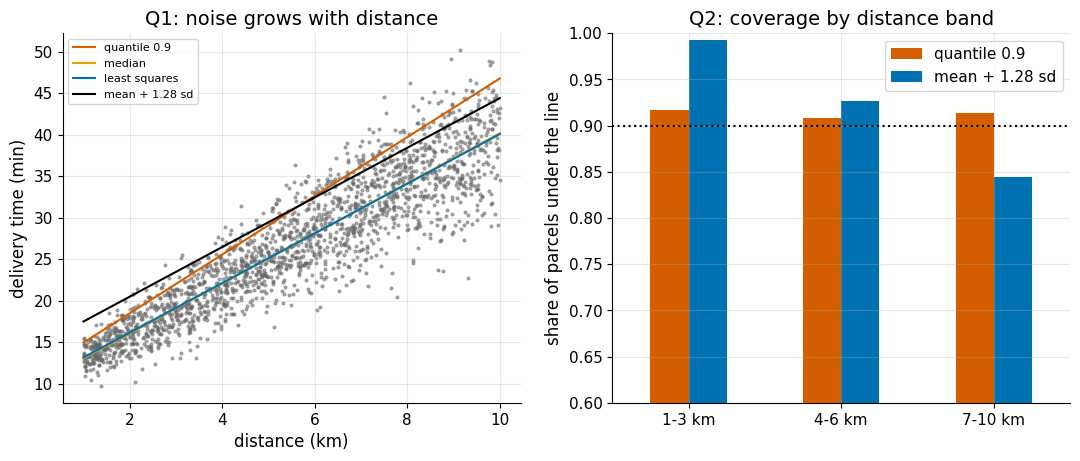

In [17]:
g = np.random.default_rng(13); n3 = 2000; x3 = g.uniform(1, 10, n3); y3 = 10 + 3 * x3 + (1 + 0.4 * x3) * g.normal(size=n3); X3 = np.column_stack([np.ones(n3), x3])
def quant_reg(X, y, tau):
    n, p = X.shape; c = np.r_[np.zeros(p), tau * np.ones(n), (1 - tau) * np.ones(n)]; A = np.hstack([X, np.eye(n), -np.eye(n)]); res = linprog(c, A_eq=A, b_eq=y, bounds=[(None, None)] * p + [(0, None)] * (2 * n), method="highs"); return res.x[:p]
q90 = quant_reg(X3, y3, 0.9); q50 = quant_reg(X3, y3, 0.5); ols3 = np.linalg.lstsq(X3, y3, rcond=None)[0]; sd_res = np.std(y3 - X3 @ ols3); margin_line = ols3 + np.array([1.2816 * sd_res, 0])
xn = g.uniform(1, 10, 100_000); yn3 = 10 + 3 * xn + (1 + 0.4 * xn) * g.normal(size=xn.size); Xn = np.column_stack([np.ones(xn.size), xn]); bands = [(1, 3), (4, 6), (7, 10)]
cov = pd.DataFrame({nm: [np.mean(yn3[(xn >= a) & (xn < c_)] <= (Xn @ b_)[(xn >= a) & (xn < c_)]) for a, c_ in bands] for nm, b_ in [("quantile 0.9", q90), ("mean + 1.28 sd", margin_line)]}, index=[f"{a}-{c_} km" for a, c_ in bands])
pin = lambda b_: np.mean(l_pin(yn3 - Xn @ b_, 0.9)); print(f"Q1: quantile-0.9 line: {q90.round(3)}, median line: {q50.round(3)}, least squares: {ols3.round(3)} (truth of the 0.9 quantile: 10 + 1.2816 + (3 + 0.5126) x)"); print("Q2 coverage of new deliveries:"); print(cov.round(3).to_string())
print(f"Q3: pinball-0.9 loss on new data: quantile regression {pin(q90):.4f}, mean + 1.28 sd {pin(margin_line):.4f}; overall coverage {np.mean(yn3 <= Xn @ q90):.4f} vs {np.mean(yn3 <= Xn @ margin_line):.4f}")
assert abs(q90[1] - 3.5126) < 0.15 and abs(np.mean(yn3 <= Xn @ q90) - 0.9) < 0.02 and pin(q90) < pin(margin_line) and abs(cov.iloc[0, 1] - 0.9) > 0.03 and abs(cov.iloc[:, 0] - 0.9).max() < 0.03
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].scatter(x3, y3, s=4, color=NEUTRAL, alpha=0.5); xg = np.linspace(1, 10, 50)
for b_, nm, colr in [(q90, "quantile 0.9", HIGHLIGHT), (q50, "median", SIM), (ols3, "least squares", MAIN), (margin_line, "mean + 1.28 sd", "black")]: axes[0].plot(xg, b_[0] + b_[1] * xg, color=colr, label=nm)
axes[0].legend(fontsize=8); axes[0].set_xlabel("distance (km)"); axes[0].set_ylabel("delivery time (min)"); axes[0].set_title("Q1: noise grows with distance")
cov.plot(kind="bar", ax=axes[1], color=[HIGHLIGHT, MAIN]); axes[1].axhline(0.9, color="black", linestyle=":"); axes[1].set_ylim(0.6, 1.0); axes[1].set_ylabel("share of parcels under the line"); axes[1].set_title("Q2: coverage by distance band"); axes[1].tick_params(axis="x", rotation=0)
plt.show()

### 12.9 Interpretation and decision (Example 3)
- The fitted 90th-percentile line is **11.39 + 3.539 x** against the true $11.28+3.513x$; the median line (10.01 + 3.017 x) and least squares (10.16 + 2.992 x) are close to the true centre $10+3x$.
- Coverage of 100,000 new deliveries by the quantile line is **91.7 %, 90.8 % and 91.3 %** in the three distance bands (overall 91.3 %). The "mean + 1.28 SD" rule gives **99.3 %** for short trips and only **84.5 %** for long trips, where the real noise is larger than the average.
- The pinball loss at $\tau=0.9$ on new data is **0.563** for quantile regression against **0.613** for the margin rule (8 % higher).
- **Decision.** Promise delivery times with quantile regression (or a model for the spread as well as the mean); a flat margin on top of a mean forecast over-promises where the noise is small and under-delivers where it is large.

---
### Example 4: why a sigmoid output is trained with cross-entropy

**Scenario.** A one-parameter classifier predicts $q=\sigma(wx)$ for the label $y=1$ with the feature $x=1$. It starts badly wrong at $w=-6$. We train by gradient descent with the same learning rate (0.5) with (a) cross-entropy and (b) squared error $(q-y)^2$.

**Questions.** (1) What are the two gradients at the start, and the ratio? (2) How many steps does each loss need to reach $q\ge0.9$? (3) Repeat from 1,000 random starting values $w_0\sim N(-3,2^2)$: what share of runs has still not reached $q\ge0.9$ after 200 steps?

Q1: q0 = 0.00247; gradient of cross-entropy -0.99753, of squared error -0.0049208; ratio 203
Q2: steps to q >= 0.9 from w = -6: cross-entropy 34, squared error inf


Q3: still below 0.9 after 200 steps: cross-entropy 0.000, squared error 0.188; median steps (finite): 28 vs 95


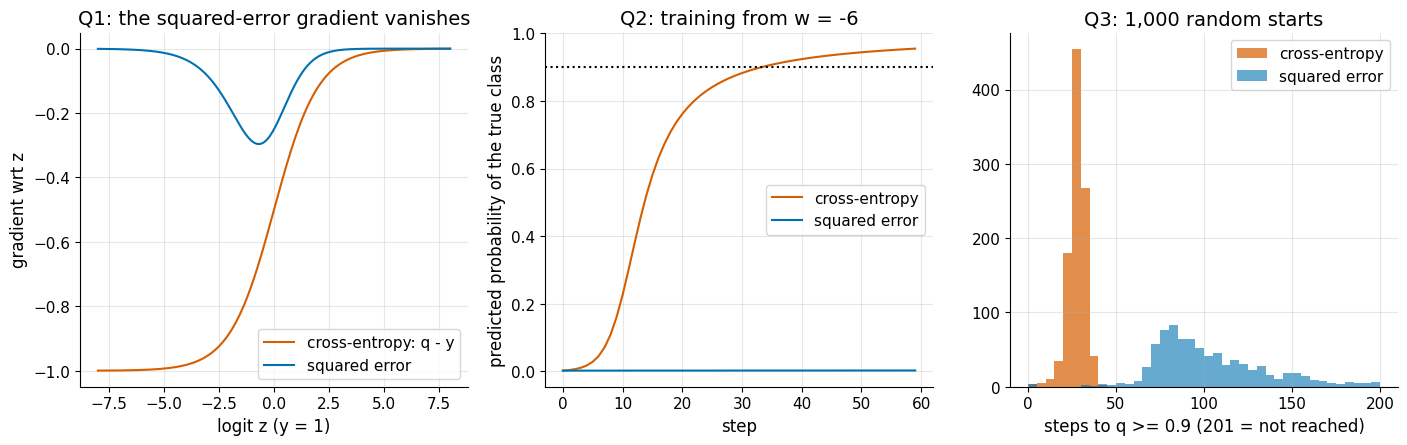

In [18]:
sg = lambda z: 1 / (1 + np.exp(-z)); w0 = -6.0; q0 = sg(w0); g_ce = q0 - 1; g_mse = 2 * (q0 - 1) * q0 * (1 - q0); print(f"Q1: q0 = {q0:.5f}; gradient of cross-entropy {g_ce:.5f}, of squared error {g_mse:.7f}; ratio {g_ce / g_mse:.0f}")
def steps(w, kind, lr=0.5, maxs=200):
    for s in range(maxs + 1):
        q = sg(w)
        if q >= 0.9: return s
        w -= lr * ((q - 1) if kind == "ce" else 2 * (q - 1) * q * (1 - q))
    return np.inf
s_ce, s_mse = steps(w0, "ce"), steps(w0, "mse"); print(f"Q2: steps to q >= 0.9 from w = -6: cross-entropy {s_ce}, squared error {s_mse}")
g = np.random.default_rng(14); w0s = g.normal(-3, 2, 1000); r_ce = np.array([steps(w, "ce") for w in w0s]); r_mse = np.array([steps(w, "mse") for w in w0s])
print(f"Q3: still below 0.9 after 200 steps: cross-entropy {np.mean(np.isinf(r_ce)):.3f}, squared error {np.mean(np.isinf(r_mse)):.3f}; median steps (finite): {np.median(r_ce[np.isfinite(r_ce)]):.0f} vs {np.median(r_mse[np.isfinite(r_mse)]):.0f}")
assert abs(g_ce + 0.99753) < 1e-4 and g_ce / g_mse > 150 and s_ce < 50 and s_mse > 5 * s_ce and np.mean(np.isinf(r_mse)) > np.mean(np.isinf(r_ce))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6)); zz = np.linspace(-8, 8, 400); axes[0].plot(zz, -(1 - sg(zz)), color=HIGHLIGHT, label="cross-entropy: q - y"); axes[0].plot(zz, 2 * (sg(zz) - 1) * sg(zz) * (1 - sg(zz)), color=MAIN, label="squared error"); axes[0].set_xlabel("logit z (y = 1)"); axes[0].set_ylabel("gradient wrt z"); axes[0].legend(); axes[0].set_title("Q1: the squared-error gradient vanishes")
for kind, colr in [("ce", HIGHLIGHT), ("mse", MAIN)]:
    w = w0; path = []
    for _ in range(60): q = sg(w); path.append(q); w -= 0.5 * ((q - 1) if kind == "ce" else 2 * (q - 1) * q * (1 - q))
    axes[1].plot(path, color=colr, label="cross-entropy" if kind == "ce" else "squared error")
axes[1].axhline(0.9, color="black", linestyle=":"); axes[1].set_xlabel("step"); axes[1].set_ylabel("predicted probability of the true class"); axes[1].legend(); axes[1].set_title("Q2: training from w = -6")
axes[2].hist(np.minimum(r_ce, 201), bins=np.arange(0, 205, 5), color=HIGHLIGHT, alpha=0.7, label="cross-entropy"); axes[2].hist(np.minimum(r_mse, 201), bins=np.arange(0, 205, 5), color=MAIN, alpha=0.6, label="squared error"); axes[2].set_xlabel("steps to q >= 0.9 (201 = not reached)"); axes[2].legend(); axes[2].set_title("Q3: 1,000 random starts")
plt.show()

### 12.11 Interpretation and decision (Example 4)
- At $w=-6$ the predicted probability of the true class is 0.0025. The cross-entropy gradient is **-0.9975** and the squared-error gradient **-0.0049**, **203 times smaller**.
- With the same learning rate (0.5) cross-entropy reaches $q\ge0.9$ in **34 steps**, while squared error has **not reached it after 200 steps**.
- From 1,000 random starts ($w_0\sim N(-3,2^2)$): **0 %** of the cross-entropy runs but **18.8 %** of the squared-error runs are still below 0.9 after 200 steps, and the median number of steps among the successful runs is 28 against 95.
- **Decision.** Train probability outputs (sigmoid or softmax) with cross-entropy: the gradient $q-y$ stays proportional to the error however wrong the model is; squared error is the right loss for a Gaussian regression head, not for a saturating probability.

## 13. Where it is used

### Statistics
- **Maximum likelihood** for every parametric model; **M-estimation and robust statistics** (Huber, Tukey); **quantile regression** in economics and risk; **generalised linear models** (09_02) pair a noise family with a link.

### Data science
- **Forecasting** with quantile losses (inventory, capacity, SLAs), **count models** (demand, arrivals), **robust regression** for dirty data, **evaluation metrics** (RMSE for means, MAE for medians, log loss for probabilities).

### ML and AI
- **Neural-network training:** regression heads (MSE, Huber, pinball), classification heads (cross-entropy), language models (token cross-entropy, perplexity), **probabilistic heads** that predict a mean and variance (Gaussian NLL), mixture density networks, and the choice of loss as an implicit **noise assumption**.

## 14. Common pitfalls and misconceptions

- **Using MSE because it is the default:** with heavy tails or outliers it estimates a mean dragged by the extremes (Example 1); with counts it can predict negative rates (Example 2).
- **Optimising the mean when the business needs a quantile:** a 90 % service level needs the pinball loss, not the mean plus a guess (Example 3).
- **Squared error on probabilities:** with sigmoid or softmax outputs it learns slowly when the model is confidently wrong (Example 4); use cross-entropy.
- **Comparing losses across models with different noise assumptions:** NLL values from different distributions are comparable only if the densities are over the same variable.
- **Forgetting the scale parameter:** the Gaussian NLL depends on $\sigma$; fixing it to 1 only equals MSE up to a constant.
- **Clipping probabilities:** a log loss of exactly 0 or infinity is a bug; clip to $[\epsilon,1-\epsilon]$.
- **Thinking MAE is "unbiased":** it is unbiased for the median, which differs from the mean for skewed targets.

## 15. Exercises

1. Show that for the data $(1,2,3,4,100)$ the constant minimising squared error is 22 and the one minimising absolute error is 3, and compute the Huber (delta 1) minimiser numerically.
2. A model predicts 12 for a delivery that took 20 minutes. Compute the pinball loss for $\tau=0.9$ and $\tau=0.1$. Which quantile model is penalised harder, and why?
3. A Poisson model predicts a rate of 2.5 for an hour in which 6 rentals occurred. Compute the Poisson NLL contribution (including the constant) and the gradient with respect to $\log\lambda$.
4. For a Laplace noise model with $b=2$ compute the density at residuals 0, 2 and 6, and the NLL for the residuals $(-1,0.5,3)$.
5. A binary classifier gives $q=0.01$ to a positive example. Compute the cross-entropy loss, the squared error, and both gradients with respect to the logit.
6. (Harder) Fit the Student-$t$ location with $\nu=3$ to the sample $(9.8,10.1,10.0,10.3,9.9,35)$ by minimising the NLL, and compare with the mean and median.

Solutions are at the end.

## 16. Summary table

| Loss | Likelihood | Learns | Robust? |
|---|---|---|---|
| MSE | Gaussian | mean | no |
| MAE | Laplace | median | yes |
| Huber | Gaussian centre, Laplace tails | robust mean | yes |
| Pinball $\tau$ | asymmetric Laplace | $\tau$-quantile | yes |
| Cross-entropy | Bernoulli / categorical | probability | n/a |
| Poisson | Poisson | mean count | n/a |
| Student-$t$ | $t_\nu$ | centre | yes |
| Gradient of CE with a sigmoid | $q-y$ | | no vanishing |
| tools | `scipy.optimize`, `linprog`, `stats.*.logpdf` | | |

## Solutions

In [19]:
d1 = np.array([1, 2, 3, 4, 100.0]); hub = minimize_scalar(lambda c: l_huber(d1 - c).sum(), bounds=(0, 100), method="bounded").x; print(f"1: mean {d1.mean()}, median {np.median(d1)}, Huber minimiser {hub:.3f}")
print(f"2: pinball tau = 0.9: {l_pin(20 - 12, 0.9):.2f}, tau = 0.1: {l_pin(20 - 12, 0.1):.2f} (the 0.9 model is punished more for under-predicting)")
lam = 2.5; print(f"3: NLL = {lam - 6 * np.log(lam) + np.sum(np.log(np.arange(1, 7))):.4f} (= {-stats.poisson.logpmf(6, lam):.4f}), gradient wrt log lambda = {lam - 6}")
print("4: Laplace(b = 2) density at 0, 2, 6:", np.round(stats.laplace.pdf([0, 2, 6], 0, 2), 4), "| NLL of (-1, 0.5, 3):", round(-stats.laplace.logpdf([-1, 0.5, 3], 0, 2).sum(), 4))
q = 0.01; z = np.log(q / (1 - q)); print(f"5: cross-entropy {-np.log(q):.4f}, squared error {(1 - q) ** 2:.4f}; gradients wrt the logit: {q - 1:.4f} and {2 * (q - 1) * q * (1 - q):.5f}")
s6 = np.array([9.8, 10.1, 10.0, 10.3, 9.9, 35.0]); t6 = minimize_scalar(lambda c: l_t(s6 - c, 3.0, 0.3).sum(), bounds=(5, 40), method="bounded").x; print(f"6: t3 location {t6:.3f} vs mean {s6.mean():.3f} vs median {np.median(s6):.3f}")
assert abs(hub - 3.0) < 1.5 and abs(-stats.poisson.logpmf(6, lam) - (lam - 6 * np.log(lam) + np.sum(np.log(np.arange(1, 7))))) < 1e-9 and abs(t6 - 10.0) < 0.3

1: mean 22.0, median 3.0, Huber minimiser 3.000
2: pinball tau = 0.9: 7.20, tau = 0.1: 0.80 (the 0.9 model is punished more for under-predicting)
3: NLL = 3.5815 (= 3.5815), gradient wrt log lambda = -3.5
4: Laplace(b = 2) density at 0, 2, 6: [0.25   0.092  0.0124] | NLL of (-1, 0.5, 3): 6.4089
5: cross-entropy 4.6052, squared error 0.9801; gradients wrt the logit: -0.9900 and -0.01960
6: t3 location 10.016 vs mean 14.183 vs median 10.050


**1.** The mean is **22.0**, the median **3.0**, and the Huber minimiser (delta 1) is **3.0**: one outlier moves the mean by 19 and the others not at all.

**2.** For a delivery of 20 minutes predicted at 12 the residual is 8: the pinball loss is **7.20** at $\tau=0.9$ and **0.80** at $\tau=0.1$. The 0.9 model is punished nine times harder because under-prediction is the costly error for a high quantile.

**3.** The Poisson NLL is $2.5-6\ln2.5+\ln720=$ **3.5815** (equal to `-poisson.logpmf(6, 2.5)`) and the gradient with respect to $\log\lambda$ is $\lambda-y=$ **-3.5**: the log-rate should increase.

**4.** The Laplace($b=2$) density at residuals 0, 2 and 6 is **0.2500, 0.0920 and 0.0124**; the NLL of $(-1,0.5,3)$ is **6.4089**.

**5.** Cross-entropy **4.605**, squared error **0.980**; the gradients with respect to the logit are **-0.990** (cross-entropy) and **-0.0196** (squared error): 50 times smaller.

**6.** The $t_3$ location is **10.016**, the median 10.050 and the mean **14.183**: the outlier 35 drags the mean by 4 minutes but barely moves the $t$ estimate.